# 04 - Features par partie : analyse approfondie

**But** : à partir de `blitz_180_parties.parquet` (notebook 03, 1 ligne par partie), construire des variables qui aident à prédire
`elo_moyen`, **mesurer** ce que chacune apporte, et ne garder que celles qui le méritent.

**Règles du jeu**
- Les features viennent **uniquement des coups et de la pendule** (aucun Elo, résultat ou `RatingDiff`).
- Toute l'analyse (corrélations, seuils, sélection) se fait sur le **train**. Le **valid** ne sert qu'à vérifier à la fin (section 7).
  Le **test n'est jamais ouvert** dans ce notebook.
- Chaque nouvelle feature est testée : relation avec l'Elo, valeurs manquantes, effet de la cadence et de la longueur de partie, redondance.

| # | Contenu |
|---|---|
| 0 | Chargement |
| 1 | Pendule et coups : du joueur à la partie |
| 2 | Nouvelles features : pendule, ouverture, matériel (python-chess), partie |
| 3 | Assemblage |
| 4 | Lien avec l'Elo : corrélation **et** non-linéarité |
| 5 | Robustesse : cadence, longueur, valeurs manquantes, redondance |
| 6 | Sélection |
| 7 | Validation : ce que gagne un modèle (par famille de features) |
| 8 | Sauvegarde et fiche |

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import plotly.express as px
import polars as pl
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from utils.features import COUPS, PENDULE
from utils.features_partie import (
    MATERIEL, PARTIE, PENDULE_PLUS, calcule_materiel, features_pendule_coups, profondeur_theorie,
)

warnings.filterwarnings("ignore", category=DeprecationWarning)

PARTIES_PATH = Path("../Data/blitz_180_parties.parquet")
MAT_PATH = Path("../Data/blitz_180_materiel.parquet")  # cache du rejeu des parties (~1 min)
OUT_PATH = Path("../Data/blitz_180_features_partie.parquet")

SEUIL_THEORIE = 1  # section 2.2
BINS = 20          # tranches pour mesurer la non-linéarité (section 4)
ETA2_MIN = 0.003   # section 6 : une feature qui explique < 0,3 % de la variance est écartée
CORR_MAX = 0.8     # section 5.4 : au-delà, deux features sont redondantes

pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(12)
plt.rcParams["figure.dpi"] = 110

## 0. Chargement

In [2]:
parties = pl.read_parquet(PARTIES_PATH)
parties.group_by("split").agg(parties=pl.len(), elo_moyen=pl.col("elo_moyen").mean().round(), n_moves=pl.col("n_moves").mean().round()).sort("split")

split,parties,elo_moyen,n_moves
str,u32,f64,f64
"""test""",8340,1688.0,71.0
"""train""",179356,1678.0,71.0
"""valid""",8428,1675.0,70.0


Quelques fonctions d'analyse utilisées partout. Deux mesures du lien avec l'Elo :
- **Spearman ρ** : relation *monotone* (plus la feature monte, plus l'Elo monte ou baisse) ;
- **η² (eta carré)** : part de la variance de l'Elo expliquée par la feature découpée en 20 tranches. Si η² ≫ ρ², la relation
  est **non monotone** (en U, en cloche…) : Spearman la sous-estime, un modèle à arbres l'exploitera.
  Les valeurs manquantes forment une tranche à part (elles peuvent être informatives).

In [3]:
CIBLE = "elo_moyen"


def rho(df, col, cible=CIBLE):
    return df.select(pl.corr(pl.col(col).cast(pl.Float64), cible, method="spearman")).item()


def eta2(df, col, cible=CIBLE, bins=BINS):
    # numérique : tranches de même effectif (par rang) ; catégoriel : une tranche par valeur
    tranche = pl.col(col) if df[col].dtype == pl.String else (pl.col(col).cast(pl.Float64).rank() / pl.col(col).count() * bins).ceil()
    g = df.select(b=tranche, y=cible).group_by("b").agg(n=pl.len(), m=pl.col("y").mean())
    mu = df[cible].mean()
    return ((g["n"] * (g["m"] - mu) ** 2).sum() / df.height) / df[cible].var()

## 1. Pendule et coups : du joueur à la partie

Le dépôt a déjà des features **par joueur** (`utils/features.py` : pendule, pièces jouées, roque…). Ici la cible est
la **moyenne des deux joueurs** : on calcule chaque feature pour les Blancs (`gather_every(2, 0)`) et pour les Noirs (`gather_every(2, 1)`),
puis on garde aussi la **moyenne des deux**. Est-ce que ça aide ? On compare, sur le train, la corrélation de la feature des Blancs seule,
des Noirs seuls, et de la moyenne.

In [4]:
pc = features_pendule_coups(parties)  # f_b, f_n et f = moyenne des deux, pour chaque feature
base = parties.select("game_id", "split", CIBLE)
train_pc = base.join(pc, on="game_id").filter(pl.col("split") == "train")

noms = [c for c in list(PENDULE) + list(COUPS) + list(PENDULE_PLUS)]
agg = pl.DataFrame(
    {"feature": noms, "blancs": [rho(train_pc, f"{c}_b") for c in noms], "noirs": [rho(train_pc, f"{c}_n") for c in noms], "moyenne": [rho(train_pc, c) for c in noms]}
).with_columns(gain=pl.col("moyenne").abs() - pl.max_horizontal(pl.col("blancs").abs(), pl.col("noirs").abs()))
print(f"features où la moyenne des deux joueurs corrèle mieux que le meilleur des deux : {(agg['gain'] > 0).sum()} sur {agg.height}")
agg.sort(pl.col("moyenne").abs(), descending=True).head(12).with_columns(pl.exclude("feature").round(3))

features où la moyenne des deux joueurs corrèle mieux que le meilleur des deux : 23 sur 28


feature,blancs,noirs,moyenne,gain
str,f64,f64,f64,f64
"""cv_temps""",0.229,0.236,0.294,0.058
"""t_ouverture""",-0.26,-0.26,-0.291,0.03
"""part_t_ouverture""",-0.269,-0.274,-0.29,0.016
"""pct_rapides""",0.232,0.239,0.27,0.031
"""t_median""",-0.203,-0.2,-0.232,0.029
"""clk_coup_10""",0.192,0.198,0.226,0.027
"""coup_t_max""",0.151,0.158,0.181,0.023
"""petit_roque""",0.1,0.144,0.167,0.023
"""pct_captures""",-0.129,-0.127,-0.16,0.031


La moyenne des deux joueurs corrèle **mieux** que chaque joueur pris seul (ex. `t_ouverture` : -0,26 pour chacun, -0,29 pour la moyenne) :
la cible est la moyenne des deux Elo, la moyenne de leurs signaux la reflète mieux et le bruit de chaque joueur se compense.
**Décision** : on garde la **moyenne des deux** (une colonne par feature au lieu de deux).

## 2. Nouvelles features

### 2.1 Pendule : temps restant à des moments précis
`clk_coup_10 / 20 / 30` : temps restant après le 10e / 20e / 30e coup du joueur (null si la partie est plus courte).
`t_median` : temps médian par coup (robuste aux grosses réflexions). `part_t_ouverture` : part du temps total passée sur les 10 premiers coups.

### 2.2 Ouverture : jusqu'où la partie reste « dans la théorie »
`profondeur_theorie` : nombre de demi-coups pendant lesquels la suite de coups a déjà été jouée au moins `seuil` fois **dans d'autres parties
du train**. Idée : un joueur qui connaît ses ouvertures reste longtemps sur des chemins connus.
Les compteurs viennent du train seul (pas de fuite), et on retire la partie elle-même quand elle est dans le train.

Le seuil est un choix : on regarde son effet sur la corrélation avec l'Elo (train).

In [5]:
essais = []
for seuil in [1, 2, 3, 5, 10, 20, 50]:
    p = profondeur_theorie(parties, seuil=seuil)
    d = parties.select("split", CIBLE).with_columns(p=p).filter(pl.col("split") == "train")
    essais.append({"seuil": seuil, "profondeur_moyenne": round(d["p"].mean(), 1), "profondeur_max": d["p"].max(), "spearman": round(rho(d, "p"), 3)})
pl.DataFrame(essais)

seuil,profondeur_moyenne,profondeur_max,spearman
i64,f64,i64,f64
1,8.6,32,0.174
2,7.9,28,0.16
3,7.5,28,0.151
5,7.1,24,0.139
10,6.5,23,0.124
20,6.0,20,0.105
50,5.3,14,0.079


Plus le seuil est bas, plus la corrélation est forte (ρ passe de 0,08 à 0,17) : ce qui compte, c'est surtout de savoir si la suite de coups a **déjà
été vue ailleurs**, pas combien de fois. On retient `SEUIL_THEORIE = 1` (« au moins une autre partie du train a joué la même suite »),
le seuil le plus simple à expliquer et le plus corrélé.

**Ouvertures catégorielles** : le 1er coup des Blancs (`ouv_blanc`), la réponse des Noirs (`ouv_noir`) et la famille ECO (`eco_lettre`, A-E).
Y a-t-il un lien avec l'Elo ?

In [6]:
train_p = parties.filter(pl.col("split") == "train").join(parties.select("game_id", **PARTIE), on="game_id")
for col in ["ouv_noir", "ouv_blanc", "eco_lettre"]:
    print(col, "| valeurs :", train_p[col].n_unique(), "| eta2 =", round(eta2(train_p, col), 3))
print(train_p.group_by("eco_lettre").agg(parties=pl.len(), elo_moyen=pl.col(CIBLE).mean().round()).sort("eco_lettre"))
(
    train_p.group_by("ouv_noir").agg(parties=pl.len(), elo_moyen=pl.col(CIBLE).mean().round())
    .filter(pl.col("parties") >= 2000).sort("elo_moyen")
)

ouv_noir | valeurs : 20 | eta2 = 0.076
ouv_blanc | valeurs : 20 | eta2 = 0.018
eco_lettre | valeurs : 5 | eta2 = 0.034
shape: (5, 3)
┌────────────┬─────────┬───────────┐
│ eco_lettre ┆ parties ┆ elo_moyen │
│ ---        ┆ ---     ┆ ---       │
│ str        ┆ u32     ┆ f64       │
╞════════════╪═════════╪═══════════╡
│ A          ┆ 44522   ┆ 1713.0    │
│ B          ┆ 55564   ┆ 1711.0    │
│ C          ┆ 50281   ┆ 1592.0    │
│ D          ┆ 25723   ┆ 1680.0    │
│ E          ┆ 3266    ┆ 1955.0    │
└────────────┴─────────┴───────────┘


ouv_noir,parties,elo_moyen
str,u32,f64
"""e5""",45771,1562.0
"""b6""",3796,1630.0
"""d5""",38473,1641.0
"""Nc6""",2640,1649.0
"""g6""",6968,1680.0
"""e6""",18314,1698.0
"""c6""",13831,1717.0
"""d6""",7421,1720.0
"""c5""",23924,1797.0


Les ouvertures sont **très informatives** (η² de `ouv_noir` ≈ 0,08 : au niveau des meilleures features de pendule) : la réponse `Nf6` (hindoise) est
jouée par des joueurs ~300 points plus forts que ceux qui répondent `e5`. Il y a peu de valeurs différentes (~20 premiers coups possibles), on les
garde telles quelles en catégories. La famille ECO (A-E) apporte moins (η² ≈ 0,03) mais reste utile : `E` (indiennes) ≈ 1950 Elo contre ≈ 1590 pour `C` (parties ouvertes `e4 e5`).

### 2.3 Matériel avec `python-chess`
On rejoue chaque partie et on note, après chaque demi-coup, le **matériel** (pion 1, cavalier 3, fou 3, tour 5, dame 9) :
- `mat` = Blancs − Noirs (qui est devant) ; `mat_tot` = Blancs + Noirs (78 au départ → quand la partie se simplifie).

Le matériel ne bouge que sur une prise ou une promotion, donc on ne le recompte que dans ces cas (le rejeu de 196 000 parties prend ~1 min en parallèle,
résultat mis en cache).

(196124, 3) | même parties que le dataset : True


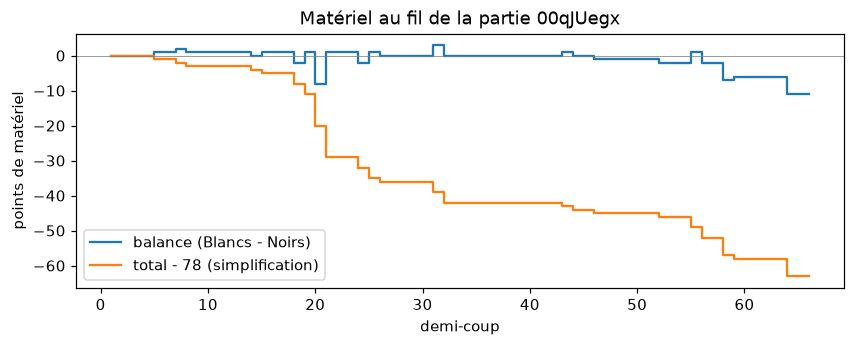

In [7]:
if not MAT_PATH.exists():
    calcule_materiel(parties).write_parquet(MAT_PATH)
mat = pl.read_parquet(MAT_PATH)
print(mat.shape, "| même parties que le dataset :", set(mat["game_id"]) == set(parties["game_id"]))

# Une partie de longueur médiane, pour voir ce que ça donne
ex = parties.filter(pl.col("n_moves") == parties["n_moves"].median()).head(1)["game_id"][0]
courbe = mat.filter(pl.col("game_id") == ex)
fig, ax = plt.subplots(figsize=(9, 3))
ax.step(range(1, courbe["mat"][0].len() + 1), courbe["mat"][0], label="balance (Blancs - Noirs)", where="post")
ax.step(range(1, courbe["mat_tot"][0].len() + 1), [t - 78 for t in courbe["mat_tot"][0]], label="total - 78 (simplification)", where="post")
ax.axhline(0, color="gray", lw=0.5)
ax.set(xlabel="demi-coup", ylabel="points de matériel", title=f"Matériel au fil de la partie {ex}")
ax.legend()
plt.show()

Features dérivées (par partie) :

| feature | définition | idée |
|---|---|---|
| `mat_abs_moy` / `mat_abs_max` / `mat_abs_fin` | écart de matériel moyen / maximal / final (valeur absolue) | les parties de faibles niveaux sont plus déséquilibrées : on laisse des pièces |
| `mat_tot_20 / 40 / 60` | matériel total restant au demi-coup 20 / 40 / 60 (null si plus courte) | rythme de simplification |
| `mat_tot_fin` | matériel total à la fin | |
| `ply_finale` | 1er demi-coup où il reste ≤ 40 points (null si jamais) | entrée en finale |
| `n_gratuites` | pièce (≥ 3 pts) prise et **non reprise** au coup suivant | proxy d'une **gaffe** (sans Stockfish) |

`n_gratuites` croît mécaniquement avec la longueur de la partie : on la ramène à un **taux** (pour 100 demi-coups) : `taux_gratuites`. (Brute, elle ne corrélait quasiment pas avec l'Elo, ρ = -0,02 ; en taux, c'est l'une des meilleures nouvelles features.)

### 2.4 Autres features de partie
`fini_par_mat` (dernier coup = mat), `premiere_prise` (demi-coup de la 1re prise), `n_moves` (longueur).

## 3. Assemblage

In [8]:
nom_moy = [c for c in pc.columns if not c.endswith(("_b", "_n")) and c != "game_id"]

feats = (
    parties.select("game_id", "blanc", "noir", "split", CIBLE, "cadence", "eco", "n_moves")
    .join(pc.select("game_id", *nom_moy), on="game_id", how="left")
    .join(mat.select("game_id", **MATERIEL), on="game_id", how="left")
    .join(parties.select("game_id", **PARTIE), on="game_id", how="left")
    .join(parties.select("game_id", profondeur_theorie=profondeur_theorie(parties, SEUIL_THEORIE)), on="game_id", how="left")
    .with_columns(taux_gratuites=pl.col("n_gratuites") / pl.col("n_moves") * 100)
    .drop("n_gratuites")
)

FAMILLES = {
    "pendule": list(PENDULE) + list(PENDULE_PLUS),
    "coups": list(COUPS),
    "ouverture": ["profondeur_theorie", "ouv_blanc", "ouv_noir", "eco_lettre"],
    "materiel": [c for c in MATERIEL if c != "n_gratuites"] + ["taux_gratuites"],
    "partie": ["n_moves", "fini_par_mat", "premiere_prise", "cadence"],
}
CATS = ["cadence", "ouv_blanc", "ouv_noir", "eco_lettre"]
NUM = [c for f in FAMILLES.values() for c in f if c not in CATS]
famille_de = {c: f for f, cols in FAMILLES.items() for c in cols}
print(feats.shape, "|", len(NUM), "features numériques +", len(CATS), "catégorielles")

(196124, 51) | 41 features numériques + 4 catégorielles


### Contrôles de base : valeurs manquantes, infinies, aberrantes

In [9]:
flottants = [c for c in NUM if feats[c].dtype.is_float()]
print("NaN :", feats.select(pl.col(flottants).is_nan().sum()).sum_horizontal().item(), "| infinis :", feats.select(pl.col(flottants).is_infinite().sum()).sum_horizontal().item())
(
    feats.select(
        [pl.col(c).cast(pl.Float64).min().alias(f"{c}|min") for c in NUM]
        + [pl.col(c).cast(pl.Float64).max().alias(f"{c}|max") for c in NUM]
        + [(pl.col(c).null_count() / feats.height * 100).round(1).alias(f"{c}|pct_null") for c in NUM]
    )
    .unpivot().with_columns(pl.col("variable").str.split("|").list.to_struct(fields=["feature", "stat"])).unnest("variable")
    .pivot(on="stat", index="feature", values="value")
    .filter((pl.col("pct_null") > 0) | (pl.col("max") > 10_000))
    .sort("pct_null", descending=True)
)

NaN : 0 | infinis : 0


feature,min,max,pct_null
str,f64,f64,f64
"""mat_tot_60""",5.0,78.0,41.3
"""clk_coup_30""",0.0,200.5,39.8
"""ply_finale""",19.0,143.0,38.2
"""t_finale""",0.0,62.0,28.1
"""mat_tot_40""",12.0,78.0,14.3
"""clk_coup_20""",1.0,201.0,13.1
"""coup_du_roque""",4.0,39.0,5.2
"""t_milieu""",0.0,115.0,0.3
"""premiere_prise""",3.0,77.0,0.1


Pas de NaN ni d'infinis. Les seules valeurs manquantes viennent de **parties trop courtes pour atteindre un moment donné** (`t_finale`, `clk_coup_30`,
`mat_tot_60`…) ou d'événements qui n'ont pas eu lieu (`coup_du_roque` sans roque, `ply_finale` sans finale). Ces « manquants » ont un sens :
on les garde `null` (section 5.3).

## 4. Lien avec l'Elo : corrélation et non-linéarité (train)

In [10]:
train = feats.filter(pl.col("split") == "train")
bilan = pl.DataFrame(
    {
        "feature": NUM + CATS,
        "famille": [famille_de[c] for c in NUM + CATS],
        "spearman": [rho(train, c) for c in NUM] + [None] * len(CATS),
        "eta2": [eta2(train, c) for c in NUM + CATS],
        "pct_null": [round(train[c].null_count() / train.height * 100, 1) for c in NUM + CATS],
    }
).with_columns(rho2=pl.col("spearman") ** 2).sort("eta2", descending=True)
bilan.with_columns(pl.col("spearman", "eta2", "rho2").round(3))

feature,famille,spearman,eta2,pct_null,rho2
str,str,f64,f64,f64,f64
"""cv_temps""","""pendule""",0.294,0.091,0.0,0.086
"""t_ouverture""","""pendule""",-0.291,0.088,0.0,0.085
"""part_t_ouverture""","""pendule""",-0.29,0.087,0.0,0.084
"""pct_rapides""","""pendule""",0.27,0.083,0.0,0.073
"""ouv_noir""","""ouverture""",null,0.076,0.0,null
"""clk_coup_10""","""pendule""",0.226,0.068,0.0,0.051
"""mat_abs_moy""","""materiel""",-0.23,0.064,0.0,0.053
"""t_median""","""pendule""",-0.232,0.061,0.0,0.054
"""taux_gratuites""","""materiel""",-0.19,0.046,0.0,0.036


In [11]:
# Au-dessus de la diagonale : eta2 > rho2 = relation non monotone (Spearman la sous-estime)
nums = bilan.drop_nulls("spearman")
fig = px.scatter(nums, x="rho2", y="eta2", color="famille", hover_name="feature", text="feature", height=550,
                 title="Variance de l'Elo expliquée : relation monotone (rho²) vs toutes formes (eta²)")
fig.add_shape(type="line", x0=0, y0=0, x1=0.09, y1=0.09, line=dict(dash="dash", color="gray"))
fig.update_traces(textposition="top center", textfont_size=9)
fig.show()

**Lecture**
- Les meilleures features expliquent **~9 % de la variance** de l'Elo (η² ≈ 0,09) : `cv_temps`, `t_ouverture`, `part_t_ouverture`, `pct_rapides`.
  Aucune ne suffit seule ; c'est leur **combinaison** qui comptera (section 7).
- Les nouvelles features entrent dans le haut du classement : `ouv_noir` (7,6 %), `clk_coup_10` (6,8 %), `mat_abs_moy` (6,4 %), `taux_gratuites` (4,6 %),
  `mat_tot_40` et `mat_tot_20` (4 %), `profondeur_theorie` (3,6 %).
- Pour la plupart, η² ≈ ρ² : les relations sont **à peu près monotones** quand on moyenne les deux joueurs. Les relations en U notées en 01 sur
  un seul joueur s'adoucissent. Exceptions (η² ≫ ρ²) : `premiere_prise`, `pct_longs`, `pct_roi`, `pct_pions`, `clk_coup_30`, `t_finale` — mais leur η² est faible
  (≤ 2 %) : relations en cloche ou en marche, de toute façon peu utiles.
- `ouv_noir` et `ouv_blanc` font partie des plus informatives parmi les catégorielles (voir η² dans le tableau).

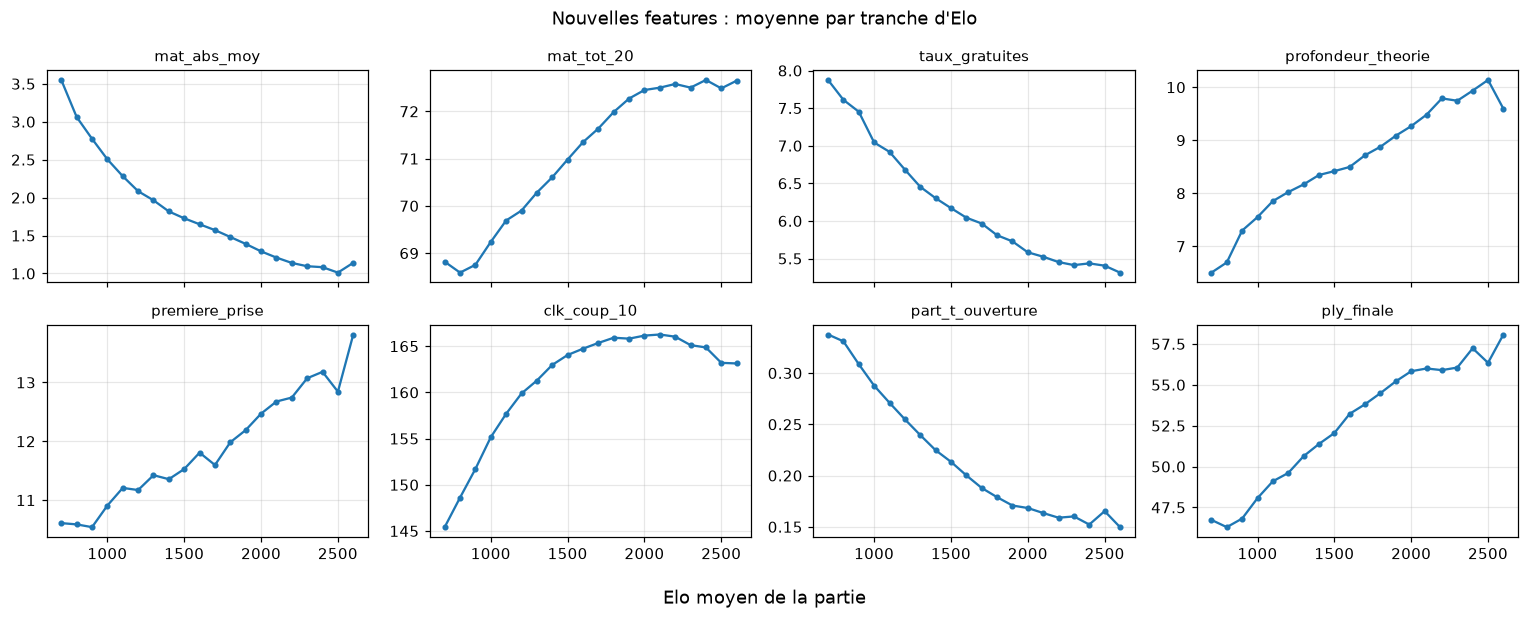

In [12]:
def courbes(df, cols, titre, pas=100, n_min=300):
    t = (
        df.with_columns(tranche=pl.col(CIBLE) // pas * pas)
        .group_by("tranche").agg(n=pl.len(), *[pl.col(c).cast(pl.Float64).mean() for c in cols])
        .filter(pl.col("n") >= n_min).sort("tranche")
    )
    lignes = -(-len(cols) // 4)
    fig, axes = plt.subplots(lignes, 4, figsize=(14, 2.8 * lignes), sharex=True, squeeze=False)
    for ax, c in zip(axes.flat, cols):
        ax.plot(t["tranche"], t[c], marker=".")
        ax.set_title(c, fontsize=10)
        ax.grid(alpha=0.3)
    for ax in axes.flat[len(cols):]:
        ax.axis("off")
    fig.suptitle(titre)
    fig.supxlabel("Elo moyen de la partie")
    fig.tight_layout()
    plt.show()


courbes(train, ["mat_abs_moy", "mat_tot_20", "taux_gratuites", "profondeur_theorie", "premiere_prise", "clk_coup_10", "part_t_ouverture", "ply_finale"],
        "Nouvelles features : moyenne par tranche d'Elo")

- `mat_abs_moy` baisse nettement avec l'Elo (les forts ne laissent pas de grosses différences de matériel) ; `mat_tot_20` monte (plus de pièces
  restantes au coup 20 chez les forts : moins d'échanges précipités) ;
- `profondeur_theorie` monte avec l'Elo ; `clk_coup_10` et `part_t_ouverture` aussi (les forts jouent leur ouverture vite) ;
- `taux_gratuites` (notre proxy de « gaffe ») **baisse avec l'Elo** : les faibles laissent plus souvent une pièce sans la reprendre. Sans moteur d'échecs,
  c'est l'une de nos meilleures mesures de la qualité des coups.

## 5. Robustesse

### 5.1 La cadence change tout ce qui touche à la pendule
En 180+2 on gagne 2 s par coup : les features de pendule n'ont pas la même valeur à Elo égal.

In [13]:
cadence = train.group_by("cadence").agg(
    parties=pl.len(), elo_moyen=pl.col(CIBLE).mean().round(), t_ouverture=pl.col("t_ouverture").mean().round(2),
    pct_rapides=pl.col("pct_rapides").mean().round(3), clk_coup_10=pl.col("clk_coup_10").mean().round(1), pct_zeitnot=pl.col("pct_zeitnot").mean().round(3),
).sort("cadence")
cadence

cadence,parties,elo_moyen,t_ouverture,pct_rapides,clk_coup_10,pct_zeitnot
str,u32,f64,f64,f64,f64,f64
"""180+0""",117063,1698.0,2.07,0.369,161.4,0.051
"""180+2""",62293,1641.0,3.38,0.247,167.6,0.066


In [14]:
clock = ["t_ouverture", "pct_rapides", "cv_temps", "clk_coup_10", "t_median", "pct_zeitnot", "temps_restant_fin", "part_t_ouverture"]
c0, c2 = train.filter(pl.col("cadence") == "180+0"), train.filter(pl.col("cadence") == "180+2")
z = lambda c: (pl.col(c) - pl.col(c).mean().over("cadence")) / pl.col(c).std().over("cadence")  # standardisé dans chaque cadence
pl.DataFrame(
    {
        "feature": clock,
        "rho_mixte": [rho(train, c) for c in clock],
        "rho_180+0": [rho(c0, c) for c in clock],
        "rho_180+2": [rho(c2, c) for c in clock],
        "rho_normalisé_par_cadence": [rho(train.with_columns(z=z(c)), "z") for c in clock],
    }
).with_columns(pl.exclude("feature").round(3))

feature,rho_mixte,rho_180+0,rho_180+2,rho_normalisé_par_cadence
str,f64,f64,f64,f64
"""t_ouverture""",-0.291,-0.326,-0.203,-0.281
"""pct_rapides""",0.27,0.31,0.165,0.259
"""cv_temps""",0.294,0.321,0.276,0.303
"""clk_coup_10""",0.226,0.326,0.203,0.281
"""t_median""",-0.232,-0.265,-0.143,-0.222
"""pct_zeitnot""",0.087,0.06,0.145,0.044
"""temps_restant_fin""",-0.111,-0.074,-0.16,-0.104
"""part_t_ouverture""",-0.29,-0.3,-0.262,-0.284


- En 180+2 on passe en moyenne **~1,3 s de plus par coup** à l'ouverture et les coups rapides (≤ 1 s) sont moins fréquents (25 % contre 37 %), alors que le niveau moyen est *plus bas* : l'incrément est dépensé.
- Les corrélations sont **plus faibles en 180+2** (ex. `t_ouverture` : -0,33 en 180+0 contre -0,20 en 180+2) : avec l'incrément, la pendule trahit moins le niveau.
- Normaliser par cadence aide pour `clk_coup_10` (0,23 → 0,28), pas pour les autres (parfois moins bien).

**Décision** : on ne normalise pas dans le dataset (ce serait un choix de modèle) mais `cadence` est une colonne obligatoire :
un arbre gère les interactions seul ; pour une régression linéaire on standardisera chaque feature de pendule **par cadence** (moyennes et écarts-types calculés sur le train).

### 5.2 La longueur de la partie n'explique-t-elle pas tout ?
Les parties longues ont mécaniquement plus de coups : des moyennes plus stables, plus de valeurs non nulles… On recalcule les corrélations dans trois
tranches de longueur : si le signal est le même, ce n'est pas un simple effet de longueur.

In [15]:
terciles = train.with_columns(longueur=pl.when(pl.col("n_moves") <= 54).then(pl.lit("1_court (<=54)")).when(pl.col("n_moves") <= 80).then(pl.lit("2_moyen (55-80)")).otherwise(pl.lit("3_long (>80)")))
top = bilan.drop_nulls("spearman").sort(pl.col("spearman").abs(), descending=True).head(12)["feature"].to_list() + ["n_moves"]
pl.DataFrame(
    {"feature": top, "global": [rho(train, c) for c in top]}
    | {k: [rho(terciles.filter(pl.col("longueur") == k), c) for c in top] for k in sorted(terciles["longueur"].unique())}
).with_columns(pl.exclude("feature").round(3))

feature,global,1_court (<=54),2_moyen (55-80),3_long (>80)
str,f64,f64,f64,f64
"""cv_temps""",0.294,0.256,0.302,0.298
"""t_ouverture""",-0.291,-0.297,-0.282,-0.249
"""part_t_ouverture""",-0.29,-0.224,-0.299,-0.285
"""pct_rapides""",0.27,0.296,0.295,0.223
"""t_median""",-0.232,-0.264,-0.225,-0.186
"""mat_abs_moy""",-0.23,-0.241,-0.322,-0.331
"""clk_coup_10""",0.226,0.232,0.229,0.185
"""mat_tot_40""",0.191,0.167,0.192,0.211
"""taux_gratuites""",-0.19,-0.18,-0.21,-0.215


Les signaux **survivent dans chaque tranche de longueur** (même ordre de grandeur) : `cv_temps`, `t_ouverture`, `pct_rapides`, `petit_roque` ne sont pas un simple effet de longueur.
Deux enseignements :
- `mat_abs_moy` est **plus forte dans les parties moyennes et longues** (≈ -0,33) que dans les courtes (-0,24) : elle mesure surtout ce qui se passe en milieu de partie ;
- `n_moves` seule, elle, **s'effondre** (0,14 → ~0,05 à longueur contrôlée) : sa corrélation globale venait surtout de la différence entre parties courtes et longues, pas d'un lien direct avec le niveau.

### 5.3 Les valeurs manquantes sont-elles informatives ?
Comparaison de l'Elo moyen quand la feature est présente ou manquante.

In [16]:
avec_null = [c for c in NUM if train[c].null_count() > 0]
pl.concat(
    [
        train.group_by(manquant=pl.col(c).is_null()).agg(n=pl.len(), elo_moyen=pl.col(CIBLE).mean().round()).with_columns(feature=pl.lit(c))
        for c in avec_null
    ]
).pivot(on="manquant", index="feature", values=["n", "elo_moyen"]).sort("feature")

feature,n_false,n_true,elo_moyen_false,elo_moyen_true
str,u32,u32,f64,f64
"""clk_coup_20""",155877,23479,1692.0,1587.0
"""clk_coup_30""",108042,71314,1713.0,1626.0
"""coup_du_roque""",170019,9337,1686.0,1539.0
"""mat_tot_40""",153812,25544,1693.0,1590.0
"""mat_tot_60""",105347,74009,1714.0,1628.0
"""ply_finale""",110929,68427,1689.0,1660.0
"""premiere_prise""",179233,123,1678.0,1682.0
"""t_finale""",129014,50342,1704.0,1613.0
"""t_milieu""",178741,615,1679.0,1515.0


Oui, nettement :
- `t_finale`, `clk_coup_20`, `clk_coup_30`, `mat_tot_40`, `mat_tot_60` manquent pour des **parties courtes**, jouées par des joueurs plus faibles
  (~90-100 points d'écart) : l'absence est un signal ;
- `coup_du_roque` manque quand personne ne roque : Elo moyen **~150 points plus bas** (1539 contre 1686) ;
- `ply_finale` (jamais de finale) : écart faible (1660 contre 1689) ; `premiere_prise` manque pour 123 parties seulement : pas de signal.

**Décision** : on garde les `null` (HistGradientBoosting les gère tels quels). Pour une régression linéaire : imputer par la médiane **et** ajouter un indicateur « manquant »
(`SimpleImputer(add_indicator=True)`, ce qu'on fait en section 7).

### 5.4 Redondance
Quand deux features ont une corrélation de rang |ρ| ≥ `CORR_MAX`, on garde celle qui explique le mieux l'Elo (η² le plus grand).

In [17]:
corr = train.select([pl.col(c).cast(pl.Float64) for c in NUM]).to_pandas().corr(method="spearman")  # pandas : seule la frontière avec numpy/sklearn
paires = sorted(
    ((a, b, corr.loc[a, b]) for i, a in enumerate(NUM) for b in NUM[i + 1:] if abs(corr.loc[a, b]) >= CORR_MAX), key=lambda p: -abs(p[2])
)
eta = dict(zip(bilan["feature"], bilan["eta2"]))
gardees, retirees = set(NUM), {}
for a, b, r in paires:
    if a in gardees and b in gardees:
        perdant = a if eta[a] < eta[b] else b
        gardees.discard(perdant)
        retirees[perdant] = f"redondante avec {b if perdant == a else a} (rho = {r:.2f})"
pl.DataFrame({"retirée": list(retirees), "raison": list(retirees.values())})

retirée,raison
str,str
"""t_median""","""redondante avec pct_rapides (r…"
"""ply_finale""","""redondante avec mat_tot_60 (rh…"
"""mat_tot_fin""","""redondante avec n_moves (rho =…"
"""t_milieu""","""redondante avec pct_longs (rho…"
"""clk_coup_30""","""redondante avec clk_coup_20 (r…"
"""pct_zeitnot""","""redondante avec temps_restant_…"


Six paires dépassent le seuil : rapidité (`pct_rapides` ~ `t_median`), finale (`mat_tot_60` ~ `ply_finale`), fin de pendule
(`pct_zeitnot` ~ `temps_restant_fin`), longueur (`mat_tot_fin` ~ `n_moves`), réflexions longues (`pct_longs` ~ `t_milieu`) et pendule tardive
(`clk_coup_20` ~ `clk_coup_30`). Aucune paire n'est identique : c'est la plus informative de chaque paire qui reste.

## 6. Sélection

On retire : (1) les features redondantes (5.4), (2) celles dont η² < `ETA2_MIN` : elles n'expliquent presque rien de l'Elo.
La sélection est faite sur le **train**. Les modèles à arbres ne sont pas gênés par des features inutiles, mais moins de colonnes =
dataset plus lisible et plus rapide, et on le vérifie en section 7.

In [18]:
inutiles = [c for c in gardees if eta[c] < ETA2_MIN]
selection = [c for c in NUM if c in gardees and c not in inutiles]

pl.concat(
    [
        pl.DataFrame({"feature": list(retirees), "décision": "retirée", "raison": list(retirees.values())}),
        pl.DataFrame({"feature": inutiles, "décision": "retirée", "raison": [f"eta2 = {eta[c]:.4f} < {ETA2_MIN}" for c in inutiles]}),
    ]
)

feature,décision,raison
str,str,str
"""t_median""","""retirée""","""redondante avec pct_rapides (r…"
"""ply_finale""","""retirée""","""redondante avec mat_tot_60 (rh…"
"""mat_tot_fin""","""retirée""","""redondante avec n_moves (rho =…"
"""t_milieu""","""retirée""","""redondante avec pct_longs (rho…"
"""clk_coup_30""","""retirée""","""redondante avec clk_coup_20 (r…"
"""pct_zeitnot""","""retirée""","""redondante avec temps_restant_…"
"""n_promotions""","""retirée""","""eta2 = 0.0001 < 0.003"""
"""pct_cavalier""","""retirée""","""eta2 = 0.0024 < 0.003"""


In [19]:
print(f"{len(selection)} features numériques gardées sur {len(NUM)} + {len(CATS)} catégorielles\n")
bilan.filter(pl.col("feature").is_in(selection + CATS)).select("feature", "famille", "eta2", "pct_null").with_columns(pl.col("eta2").round(3))

33 features numériques gardées sur 41 + 4 catégorielles



feature,famille,eta2,pct_null
str,str,f64,f64
"""cv_temps""","""pendule""",0.091,0.0
"""t_ouverture""","""pendule""",0.088,0.0
"""part_t_ouverture""","""pendule""",0.087,0.0
"""pct_rapides""","""pendule""",0.083,0.0
"""ouv_noir""","""ouverture""",0.076,0.0
"""clk_coup_10""","""pendule""",0.068,0.0
"""mat_abs_moy""","""materiel""",0.064,0.0
"""taux_gratuites""","""materiel""",0.046,0.0
"""mat_tot_40""","""materiel""",0.045,14.2


## 7. Validation : ce qu'un modèle gagne vraiment

On entraîne sur le **train**, on mesure sur le **valid** (le test reste fermé). Paramètres fixés d'avance, **aucun réglage** : on veut comparer les jeux
de features, pas optimiser un modèle. Métrique : **MAE** en points d'Elo (baseline = médiane du train).

- `HistGradientBoostingRegressor` : gère les `null` et les non-linéarités ;
- `Ridge` (régression linéaire régularisée) : imputation par la médiane + indicateur de manquant, standardisation, one-hot des catégories.

In [20]:
tr, va = feats.filter(pl.col("split") == "train"), feats.filter(pl.col("split") == "valid")
y_tr, y_va = tr[CIBLE].to_numpy(), va[CIBLE].to_numpy()
codes = pl.concat([tr, va])  # mêmes codes de catégories pour train et valid


def matrice(cols):
    exprs = [pl.col(c).cast(pl.Categorical).to_physical().cast(pl.Float64) if c in CATS else pl.col(c).cast(pl.Float64) for c in cols]
    return codes.select(exprs).to_numpy()


def mae_hgb(cols):
    X = matrice(cols)
    m = HistGradientBoostingRegressor(max_iter=500, learning_rate=0.08, early_stopping=True, random_state=0, categorical_features=[c in CATS for c in cols])
    m.fit(X[: tr.height], y_tr)
    return float(np.abs(y_va - m.predict(X[tr.height:])).mean())


baseline = float(np.abs(y_va - np.median(y_tr)).mean())
print(f"baseline (médiane du train) : MAE valid = {baseline:.1f}")

baseline (médiane du train) : MAE valid = 271.9


In [21]:
# 1) Chaque famille seule, puis toutes ensemble, puis toutes sauf une
fam_cols = {f: [c for c in cols if c in selection + CATS] for f, cols in FAMILLES.items()}
tout = [c for cols in fam_cols.values() for c in cols]

resultats = [{"jeu de features": "baseline (médiane)", "MAE valid": baseline}]
for f, cols in fam_cols.items():
    resultats.append({"jeu de features": f"{f} seule", "MAE valid": mae_hgb(cols)})
resultats.append({"jeu de features": "TOUT (sélection)", "MAE valid": mae_hgb(tout)})
for f in fam_cols:
    resultats.append({"jeu de features": f"tout sans {f}", "MAE valid": mae_hgb([c for c in tout if c not in fam_cols[f]])})
pl.DataFrame(resultats).with_columns(gain_vs_baseline=(baseline - pl.col("MAE valid")).round(1), MAE=pl.col("MAE valid").round(1)).drop("MAE valid")

jeu de features,gain_vs_baseline,MAE
str,f64,f64
"""baseline (médiane)""",0.0,271.9
"""pendule seule""",27.8,244.1
"""coups seule""",14.0,257.9
"""ouverture seule""",19.6,252.3
"""materiel seule""",21.9,250.0
"""partie seule""",7.6,264.3
"""TOUT (sélection)""",58.4,213.5
"""tout sans pendule""",43.6,228.3
"""tout sans coups""",55.9,216.0


In [22]:
# 2) Ajout cumulatif dans l'ordre : on voit ce que chaque famille apporte *en plus* des précédentes
cumul, cols = [], []
for f in ["pendule", "partie", "coups", "ouverture", "materiel"]:
    cols = cols + fam_cols[f]
    cumul.append({"famille ajoutée": f, "MAE valid": round(mae_hgb(cols), 1)})
pl.DataFrame(cumul)

famille ajoutée,MAE valid
str,f64
"""pendule""",244.1
"""partie""",240.4
"""coups""",232.6
"""ouverture""",221.8
"""materiel""",213.5


In [23]:
# 3) La sélection a-t-elle fait perdre quelque chose ? Toutes les features candidates vs la sélection
toutes = [c for c in NUM + CATS]
print(f"toutes les candidates ({len(toutes)}) : MAE = {mae_hgb(toutes):.1f} | sélection ({len(tout)}) : MAE = {mae_hgb(tout):.1f}")

# 4) Régression linéaire sur la sélection
num_sel = [c for c in tout if c not in CATS]
pandas_tout = pl.concat([tr, va]).to_pandas()
pre = ColumnTransformer(
    [
        ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), num_sel),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50), [c for c in tout if c in CATS]),
    ]
)
ridge = make_pipeline(pre, Ridge(alpha=10)).fit(pandas_tout.iloc[: tr.height], y_tr)
print(f"Ridge (sélection) : MAE = {np.abs(y_va - ridge.predict(pandas_tout.iloc[tr.height:])).mean():.1f}")

toutes les candidates (45) : MAE = 212.4 | sélection (37) : MAE = 213.5
Ridge (sélection) : MAE = 224.7


**Lecture**
- Baseline ≈ 272 → **≈ 213 avec la sélection** (HistGradientBoosting) : on gagne ~58 points d'Elo, sans aucun réglage.
- Chaque famille seule est utile mais insuffisante (la pendule est la meilleure : ≈ 244) ; **chaque famille apporte quelque chose en plus des autres**.
  Perte de MAE quand on la retire : pendule +15, ouverture +9, matériel +8, partie +3, coups +3.
- Le **matériel** (rejeu `python-chess`) est la vraie nouveauté : il apporte ~8 points en plus de toutes les autres familles, et n'existait pas dans les features
  par joueur. Les **coups SAN** (pièces jouées, captures, roque…) apportent peu en plus du reste.
- La sélection coûte ~1 point de MAE (≈ 212 avec les 45 candidates contre ≈ 213,5) : dans le bruit, on la garde pour un dataset plus lisible.
- Le modèle linéaire fait moins bien que les arbres (≈ 225, non-linéarités et interactions avec la cadence) mais reste très honnête.

⚠️ Ce sont des mesures sur le **valid** (~8 400 parties) : l'incertitude est de quelques points de MAE ; les écarts de 1-2 points ne sont pas significatifs.
Le **test** reste réservé pour la mesure finale d'un modèle choisi.

## 8. Sauvegarde et fiche

In [24]:
final = feats.select("game_id", "blanc", "noir", "split", CIBLE, "cadence", "eco", "ouv_blanc", "ouv_noir", "eco_lettre", *selection).sort("game_id")

controles = {
    "mêmes parties que `blitz_180_parties`": final["game_id"].equals(parties["game_id"].sort()),
    "split conservé": final.join(parties.select("game_id", "split"), on="game_id", suffix="_ref").filter(pl.col("split") != pl.col("split_ref")).height == 0,
    "aucun NaN / infini": final.select(pl.col(pl.Float64).is_nan().sum() + pl.col(pl.Float64).is_infinite().sum()).sum_horizontal().item() == 0,
    "cible sans null": final[CIBLE].null_count() == 0,
    "catégories sans null": final.select(pl.col(CATS).null_count()).sum_horizontal().item() == 0,
    "pas de colonne de fuite (Elo, résultat...)": not {"elo", "WhiteElo", "BlackElo", "Result", "score", "rating_diff"} & set(final.columns),
}
for nom, ok in controles.items():
    print("OK " if ok else "ECHEC", nom)
assert all(controles.values())

final.write_parquet(OUT_PATH)
print(OUT_PATH, "->", final.shape)

OK  mêmes parties que `blitz_180_parties`
OK  split conservé
OK  aucun NaN / infini
OK  cible sans null
OK  catégories sans null
OK  pas de colonne de fuite (Elo, résultat...)
..\Data\blitz_180_features_partie.parquet -> (196124, 43)


In [25]:
final.group_by("split").agg(parties=pl.len(), pct_null_moyen=(pl.concat_list(pl.col(selection)).list.eval(pl.element().is_null()).list.mean().mean() * 100).round(1))

split,parties,pct_null_moyen
str,u32,f64
"""valid""",8428,3.2
"""train""",179356,3.1
"""test""",8340,3.1


### Fiche du dataset `blitz_180_features_partie.parquet`

1 ligne = 1 partie (mêmes parties et mêmes splits que `blitz_180_parties.parquet`). Colonnes :

| Colonnes | Rôle |
|---|---|
| `game_id` | clé |
| `blanc`, `noir`, `split` | **jamais en feature** : grouper / splitter par joueur |
| `elo_moyen` | **cible** |
| `cadence`, `ouv_blanc`, `ouv_noir`, `eco_lettre` | catégorielles (one-hot ou catégories natives des arbres) |
| `eco` | code ECO complet (490 valeurs) : pour un *target encoding* **dans une validation croisée**, jamais calculé sur tout le train d'un coup |
| features numériques sélectionnées (section 6) | pendule · coups · ouverture · matériel · partie. Chaque feature est la **moyenne des Blancs et des Noirs** |

**Règles de bonne utilisation**
- Les `null` sont informatifs : arbres → tels quels ; linéaire → imputation + indicateur de manquant.
- Features de pendule : à standardiser **par cadence** pour un modèle linéaire (moyennes/écarts-types du train).
- Sélection (redondance, η²) faite sur le train ; valid sert à contrôler ; **test inutilisé**.

**Limites**
- Un seul jour, blitz 3 min : les liens pendule/Elo dépendent de la cadence (plus faibles en 180+2).
- `profondeur_theorie` dépend du train (corpus d'un jour) : à recalculer si le train change.
- Pas de moteur d'échecs : le matériel est un proxy grossier de la qualité des coups (une gaffe positionnelle ne coûte pas de pièce).

**Étapes suivantes** : modèle (HistGradientBoosting réglé par validation croisée *par groupes de joueurs*, comparé à la régression linéaire),
analyse d'erreur par tranche d'Elo, puis séquences (n-grammes de coups, réseau) et features d'échiquier plus fines (structure de pions, sécurité du roi).